# 02 — Kiểm tra dữ liệu và cố định split

Sau **01_download_data.ipynb**, notebook này thực hiện bước 2 của pipeline.md. Logic nằm trong `src/datasets/`; notebook giữ phần giải thích và lời gọi module. Chọn kernel đã cài requirements.txt, **Restart Kernel → Run All**. Không cần GPU hoặc PyTorch.

Kiểm tra ảnh–mask, thống kê, sàng lọc trùng/gần trùng, đọc quyết định rà và tái tạo split. Không sửa/xóa dữ liệu gốc. Seed 42, Kvasir 700/150/150; ClinicDB 612 ảnh external. Giữ chung các quan hệ confirmed/unsure và công bố giới hạn thiếu metadata bệnh nhân.

Split đã khóa sẽ không bị ghi đè nếu kết quả khác. Máy khác cần có các CSV quyết định trong splits/ từ Git. Không chạy lại chia tập trước mỗi lượt train.

## Thiết lập import

Tìm gốc repo tương đối để chạy được từ thư mục notebooks/ trên máy của từng thành viên.


In [1]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import display
from src.datasets.statistics import scan_datasets, resolution_statistics, assign_size_groups, save_sample_figures
from src.datasets.duplicates import fingerprint_datasets, screen_duplicates, load_review, save_confirmed_groups, draw_candidate_pairs
from src.datasets.splitting import build_split_plan, write_split_artifacts
from src.datasets.reporting import write_reports
print("Project root:", PROJECT_ROOT)


Project root: D:\DHCN\HK5\DL\Medical-Image-Segmentation


## 2.1 — Ghép cặp, thống kê và xem nhãn

`statistics.py` ghép ảnh–mask theo tên, kiểm tra số lượng và kích thước. Mask chuyển grayscale, polyp là pixel >127. Đo diện tích trên ảnh gốc. Nếu train split đã có, ngưỡng nhỏ/vừa/lớn lấy từ phân vị trên train; nếu chưa có chỉ dùng preview 5%/20%.

Overlay ở đây dùng **mask thật**, không phải dự đoán mô hình. Code không resize hay sửa dữ liệu nguồn, chỉ thu nhỏ hình hiển thị.


Kvasir-SEG: 1000 ảnh, 1000 mask
CVC-ClinicDB: 612 ảnh, 612 mask

Kvasir-SEG: 1000 cặp, 333 độ phân giải
  622x530: 78 ảnh
  626x547: 66 ảnh
  626x546: 61 ảnh
  622x529: 56 ảnh
  622x528: 53 ảnh
  622x531: 50 ảnh
  570x530: 33 ảnh
  570x531: 19 ảnh
  1348x1070: 17 ảnh
  720x576: 17 ảnh
  Xem các độ phân giải còn lại trong resolution_counts.csv.
Tỷ lệ diện tích polyp (min / trung vị / trung bình / max): 0.47% / 11.40% / 15.39% / 81.18%
Mask rỗng: 0 | Mask toàn polyp: 0
Mask có mức xám trung gian: 1000

CVC-ClinicDB: 612 cặp, 1 độ phân giải
  384x288: 612 ảnh
Tỷ lệ diện tích polyp (min / trung vị / trung bình / max): 0.34% / 6.83% / 9.17% / 48.96%
Mask rỗng: 0 | Mask toàn polyp: 0
Mask có mức xám trung gian: 138
Mốc từ 700 ảnh Kvasir train: 7.66% và 16.42%
Kvasir-SEG: nhỏ 333 | vừa 325 | lớn 342 | rỗng 0
CVC-ClinicDB: nhỏ 340 | vừa 172 | lớn 100 | rỗng 0
Quy tắc diện tích: kvasir_train_tertiles (0.0765866189188873, 0.164171694575699)
Kvasir-SEG: D:\DHCN\HK5\DL\Medical-Image-Segmentation\l

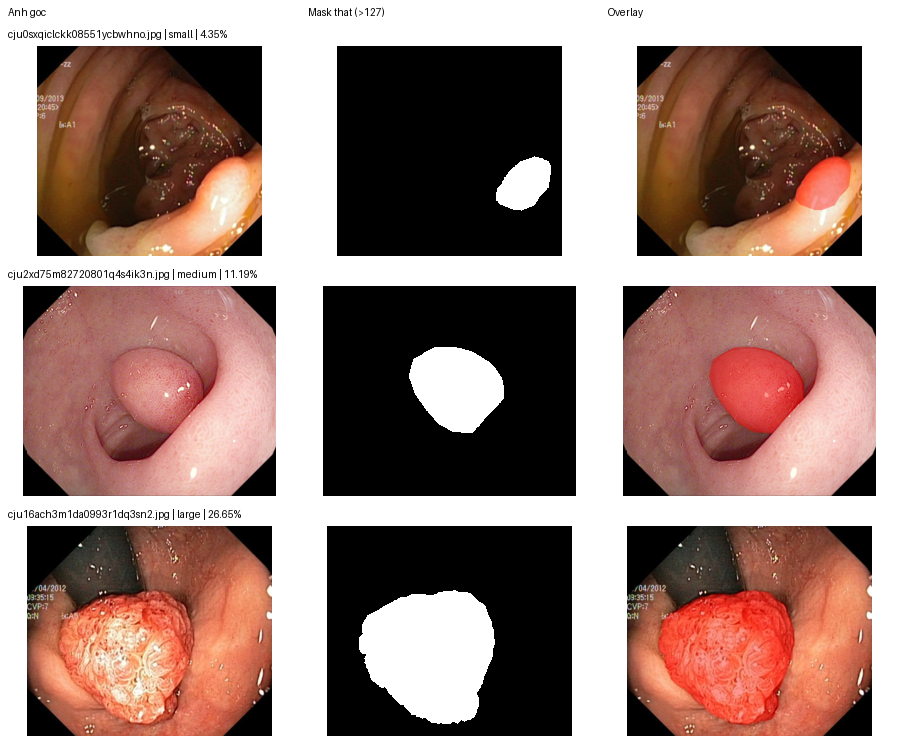

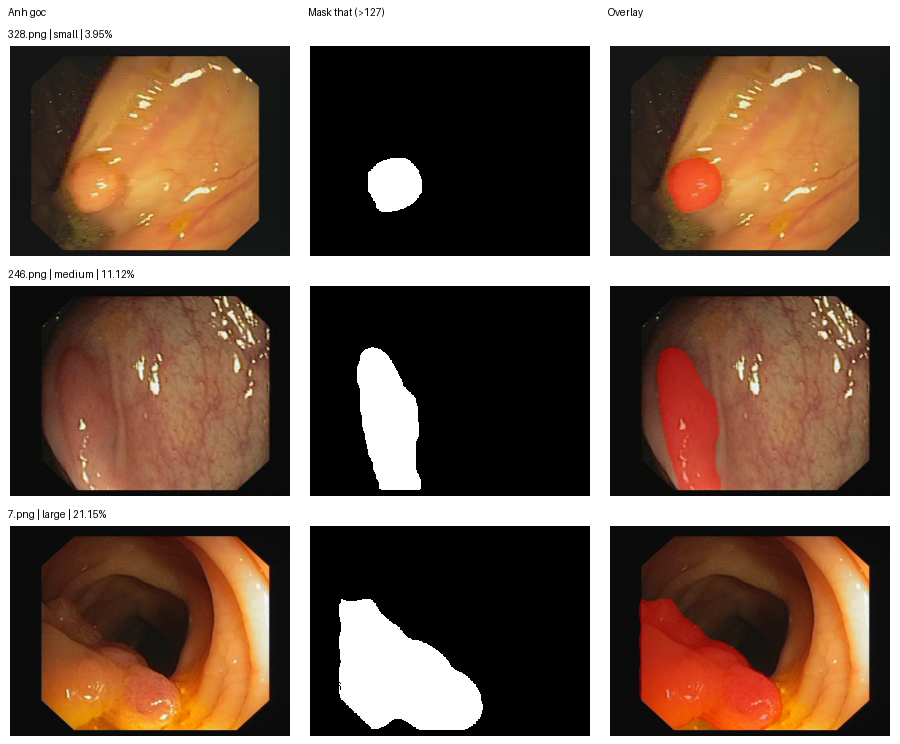

In [2]:
rows_by_dataset = scan_datasets(PROJECT_ROOT)
resolution_rows = resolution_statistics(rows_by_dataset)
size_rows, thresholds, size_rule = assign_size_groups(PROJECT_ROOT, rows_by_dataset)
print("Quy tắc diện tích:", size_rule, thresholds)
for path in save_sample_figures(PROJECT_ROOT, rows_by_dataset, PROJECT_ROOT / "logs/dataset_statistics"):
    from PIL import Image
    with Image.open(path) as image:
        display(image.copy())


## 2.2 — Sàng lọc ảnh trùng và đọc quyết định rà

`duplicates.py` so sánh SHA-256 file, SHA-256 RGB64, dHash và pHash. Chọn ứng viên khi dHash ≤6 **hoặc** pHash ≤6; giữ thêm hai cặp lịch sử nếu nằm ngoài ngưỡng. Khoảng cách có thể khác giữa phiên bản Pillow, nên lưu phiên bản và `screening_reason`.

Module đọc quyết định đã lưu từ `splits/duplicate_review.csv`, rồi nhận cập nhật trong `logs/duplicate_check/review_decisions.csv`. Quyết định cũ được kế thừa; chỉ hai cặp lịch sử đã được rà trực quan mới có mặc định unsure khi chưa có quyết định. Không tự khẳng định các cặp khác là trùng.

Different không chứng minh độc lập theo bệnh nhân. Confirmed và unsure được bảo vệ khi chia tập. Chưa rà hết các cặp trong riêng ClinicDB được ghi rõ trong báo cáo.


In [3]:
fingerprints = fingerprint_datasets(PROJECT_ROOT, rows_by_dataset)
exact_groups, near_candidates = screen_duplicates(PROJECT_ROOT, fingerprints)
review_rows = load_review(PROJECT_ROOT, near_candidates)
confirmed_groups = save_confirmed_groups(PROJECT_ROOT, fingerprints, exact_groups, review_rows)
print("Nhóm confirmed:", len(confirmed_groups))


Số cặp được so sánh: 1,298,466
Kvasir-SEG: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 59 cặp nghi gần trùng
cross_dataset: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 109 cặp nghi gần trùng
CVC-ClinicDB: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 1102 cặp nghi gần trùng
Thư mục kết quả: D:\DHCN\HK5\DL\Medical-Image-Segmentation\logs\duplicate_check
Kvasir-SEG {'confirmed': 8, 'different': 44, 'unsure': 7}
cross_dataset {'different': 109}
CVC-ClinicDB {'confirmed': 20, 'pending': 1082}
Nhóm confirmed: 24


### Xem cặp ảnh để cập nhật quyết định

Chọn scope, trang (6 cặp/trang) hoặc pair_id. Đối chiếu nếp mô và mạch máu; hình thu nhỏ chưa rõ thì xem ảnh gốc. Sửa CSV quyết định rồi chạy lại ô tổng hợp phía trên trước khi chia. Không đổi quyết định dựa vào kết quả mô hình.


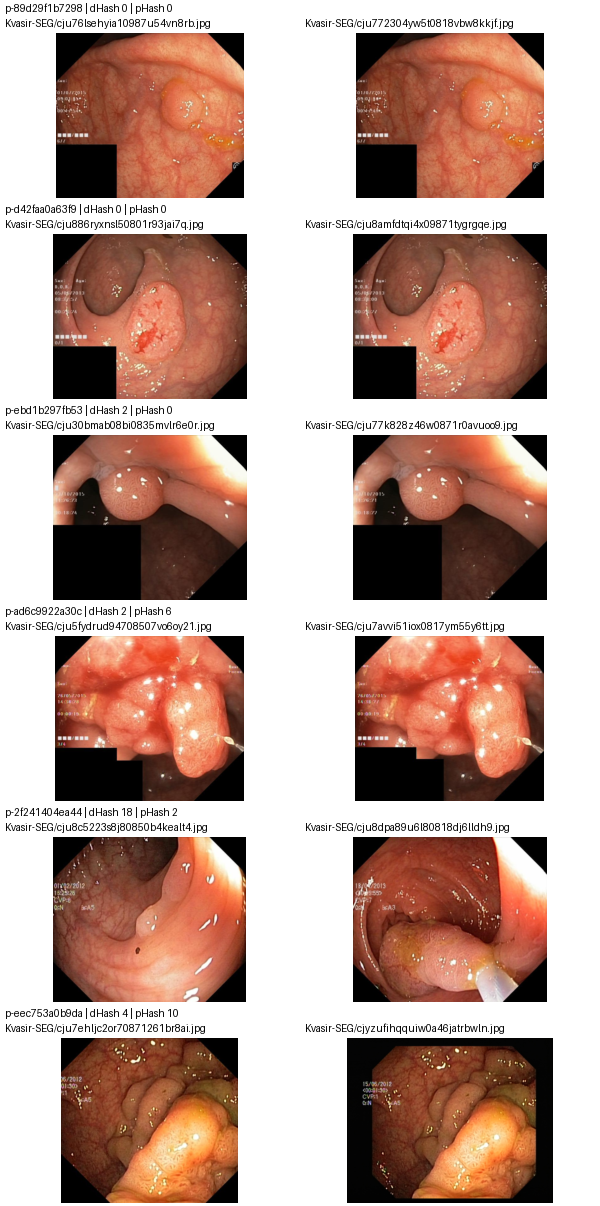

In [4]:
REVIEW_SCOPE = "Kvasir-SEG"
REVIEW_PAGE = 1
REVIEW_PAIR_ID = ""
PAIRS_PER_PAGE = 6
if REVIEW_PAIR_ID.strip():
    selected = [r for r in near_candidates if r["pair_id"] == REVIEW_PAIR_ID.strip().lower()]
    if not selected:
        raise ValueError("Không tìm thấy pair_id.")
else:
    candidates = [r for r in near_candidates if r["scope"] == REVIEW_SCOPE]
    pages = (len(candidates) + PAIRS_PER_PAGE - 1) // PAIRS_PER_PAGE
    if pages and not 1 <= REVIEW_PAGE <= pages:
        raise ValueError(f"Chọn trang trong khoảng 1–{pages}.")
    offset = (REVIEW_PAGE - 1) * PAIRS_PER_PAGE
    selected = candidates[offset:offset + PAIRS_PER_PAGE]
if selected:
    display(draw_candidate_pairs(PROJECT_ROOT / "data", selected))
else:
    print("Không có cặp để xem.")


## 2.3 — Tạo và kiểm tra kế hoạch chia tập

`splitting.py` gộp quan hệ bắc cầu thành component. Giữ cùng tập cả confirmed và unsure, không đổi unsure thành confirmed. Nếu component có cả hai dataset, loại ID Kvasir khỏi nội bộ và giữ ClinicDB external, không xóa file gốc.

Xáo trộn nhóm với seed 42, ưu tiên nhóm lớn rồi phân theo sức chứa còn lại, hướng tới 70/15/15. Kiểm tra ID tồn tại, duy nhất, không giao nhau, đủ coverage và không tách nhóm. Pending trong Kvasir hoặc giữa hai bộ sẽ chặn chia; pending trong riêng ClinicDB không chặn vì toàn bộ thuộc external.


In [5]:
plan = build_split_plan(fingerprints, exact_groups, review_rows, seed=42)
for name, ids in plan["split_ids"].items():
    print(name, len(ids))


train 700
val 150
test 150
external 612


## 2.4 — Ghi split và đối chiếu nguồn

Module kiểm tra SHA-256 mọi ảnh/mask với manifest nguồn trước khi ghi. Nếu TXT đã có nội dung khác, dừng và giữ nguyên các file. Mỗi dòng là ID không có đuôi. Lưu nhóm, review, ID bị loại, fingerprint và manifest trong `splits/` để dùng lại cho train và tái tạo.


In [7]:
manifest = write_split_artifacts(PROJECT_ROOT, rows_by_dataset, fingerprints, review_rows, plan)


Source manifest verified: 3224 image/mask files
Verified split artifacts: D:\DHCN\HK5\DL\Medical-Image-Segmentation\splits


## 2.5 — Bảng/hình báo cáo và tổng kết

`reporting.py` tính lại ngưỡng diện tích từ Kvasir train đã khóa; xuất bảng/hình trong `results/` và báo cáo Markdown. Không có patient metadata nên không khẳng định độc lập theo bệnh nhân. ClinicDB không dùng để chọn loss, checkpoint hay threshold.

Chạy ngoài notebook: `python -m scripts.prepare_data --project-root .`. Lệnh mặc định dùng dữ liệu sẵn có; thêm `--download` chỉ khi muốn chạy downloader có Internet. Chưa có mô hình train trong bước này.


In [ ]:
summary = write_reports(PROJECT_ROOT, rows_by_dataset, resolution_rows, review_rows, plan, manifest)


Mốc từ 700 ảnh Kvasir train: 7.66% và 16.42%
Kvasir-SEG: nhỏ 333 | vừa 325 | lớn 342 | rỗng 0
CVC-ClinicDB: nhỏ 340 | vừa 172 | lớn 100 | rỗng 0
Kvasir-SEG: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\figures\Kvasir-SEG_samples.png
CVC-ClinicDB: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\figures\CVC-ClinicDB_samples.png
HOÀN THÀNH BƯỚC 2
{
  "step": 2,
  "status": "complete_with_documented_screening_limits",
  "split_counts": {
    "train": 700,
    "val": 150,
    "test": 150,
    "external": 612
  },
  "mask_threshold": 127,
  "size_rule": "kvasir_train_tertiles",
  "size_thresholds_from_train": [
    0.0765866189188873,
    0.164171694575699
  ],
  "review_summary": {
    "Kvasir-SEG": {
      "confirmed": 8,
      "different": 44,
      "unsure": 7
    },
    "cross_dataset": {
      "different": 109
    },
    "CVC-ClinicDB": {
      "confirmed": 20,
      "pending": 1082
    }
  },
  "screening_counts": {
    "hash_threshold": 1270
  },
  "checks": {
    "source_mani

## Kết quả và bước tiếp theo

- Danh sách và bằng chứng chia tập: `splits/`.
- Bảng, JSON và báo cáo: `results/tables/step2_report.md`, `step2_summary.json` và các CSV.
- Hình ảnh–mask–overlay: `results/figures/`.
- Chi tiết rà ảnh: `logs/duplicate_check/`.

Tiếp theo mở **03_data_pipeline.ipynb** để xem Dataset, transforms, batch và metric. Notebook đó cần thêm requirements-training.txt. Không có mô hình train trong notebook 02.
